# 03 — Preprocessing and Time-Series Construction

**Purpose:** turn ~2 million time-stamped transactions into the forecasting series, and establish exactly **what
we forecast**.

This notebook:
1. demonstrates the timestamp normalisation;
2. rebuilds the 1-s multi-target series in memory and checks them against the stored files;
3. verifies the six previously generated UTC series (`data/processed/flashbots/`) bin for bin, without
   regenerating them;
4. documents missing intervals;
5. defines and justifies the forecasting target.

Code under test: `Flashbots/time_series/build_target_series.py`. Decisions: `Flashbots/preprocessing/PREPROCESSING.md`.
This notebook writes no files.

## Setup

In [1]:
from pathlib import Path
import sys, json

ROOT = Path.cwd()
while not (ROOT / "Flashbots" / "fbcommon.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
FB = ROOT / "Flashbots"
for sub in ("", "forecasting", "evaluation", "time_series", "data_audit", "preprocessing"):
    sys.path.insert(0, str(FB / sub))

import numpy as np
import pandas as pd
import fbcommon as fc
fc.plot_style()
%matplotlib inline
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.0f}" if abs(v) >= 1e4 else f"{v:.4g}")
print("repository:", ROOT)
print({k: v for k, v in fc.environment().items() if k != "platform"})

repository: C:\OJT_SEM3\AI-Assisted-Permissioned-Blockchain-Architecture-


{'python': '3.14.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'scikit_learn': '1.9.1', 'matplotlib': '3.11.2', 'pyyaml': '6.0.3'}


In [2]:
import build_target_series as bts
VER = json.loads((FB / "time_series" / "series_verification.json").read_text(encoding="utf-8"))

## 1. Timestamp normalisation (UTC, left-closed 1-s bins)

`timestamp_ms` is Unix epoch milliseconds in UTC. There is no timezone conversion and no daylight-saving logic.
Each transaction goes to bin `floor((timestamp_ms - 00:00 UTC) / 1000)`, so bin *t* covers `[t, t+1 s)` and is
labelled by its start. A timestamp outside the file's UTC day is an error, never silently re-assigned.

In [3]:
day0 = fc.day_start_ms("2026-09-21")
demo = np.array([0, 999, 1000, 59_999, 86_399_999]) + day0
pd.DataFrame({"timestamp_ms": demo, "UTC time": pd.to_datetime(demo, unit="ms", utc=True),
              "second_of_day (bin)": bts.second_index(demo, "2026-09-21")})

,timestamp_ms,UTC time,second_of_day (bin)
0,1789948800000,2026-09-21 00:00:00+00:00,0
1,1789948800999,2026-09-21 00:00:00.999000+00:00,0
2,1789948801000,2026-09-21 00:00:01+00:00,1
3,1789948859999,2026-09-21 00:00:59.999000+00:00,59
4,1790035199999,2026-09-21 23:59:59.999000+00:00,86399


In [4]:
try:
    bts.second_index(np.array([day0 - 1]), "2026-09-21")
except ValueError as err:
    print("out-of-day timestamp rejected:", err)

out-of-day timestamp rejected: 2026-09-21: timestamps outside the UTC day


## 2. Build the 1-s target series in memory and compare with the stored files

In [5]:
built = {}
for d in fc.DATES:
    built[d] = bts.aggregate(fc.load_extract(d), d)
    # float_precision="round_trip": pandas' default fast CSV parser can be off by 1 ulp on the float medians
    stored = pd.read_csv(FB / "time_series" / f"target_series_{d}_1s.csv.gz", float_precision="round_trip")
    same = all(np.array_equal(built[d][c].to_numpy(), stored[c].to_numpy(), equal_nan=True)
               for c in ("arrival_count", "gas_limit_sum", "calldata_bytes_sum", "median_fee_cap_gwei", "median_tip_cap_gwei"))
    print(d, "rows", len(built[d]), "| transactions", int(built[d]["arrival_count"].sum()), "| identical to stored file:", same)
    assert same and len(built[d]) == 86_400
built["2026-10-12"].iloc[19_370:19_376]

2026-09-21 rows 86400 | transactions 1055934 | identical to stored file: True


2026-10-12 rows 86400 | transactions 913856 | identical to stored file: True


,timestamp_utc,date_utc,second_of_day,arrival_count,gas_limit_sum,calldata_bytes_sum,median_fee_cap_gwei,median_tip_cap_gwei
19370,2026-10-12 05:22:50+00:00,2026-10-12,19370,15,829963,1152,2,0.2
19371,2026-10-12 05:22:51+00:00,2026-10-12,19371,11,1681621,408,2,0.2
19372,2026-10-12 05:22:52+00:00,2026-10-12,19372,17,1449842,1352,2,0.2
19373,2026-10-12 05:22:53+00:00,2026-10-12,19373,8,882776,532,1.147,0.1426
19374,2026-10-12 05:22:54+00:00,2026-10-12,19374,7,610000,136,2,0.3221
19375,2026-10-12 05:22:55+00:00,2026-10-12,19375,11,1009792,476,2,0.2


## 3. Verification of the six previously generated UTC series

The original series (`series_<date>_{1,5,10}s.csv.gz`) were built by `fabric_perf.forecasting.flashbots`. Here
the counts are re-aggregated from the extract by an independent path and compared bin by bin. The two 1-s files
are also checked against the SHA-256 recorded by the frozen P2 benchmark.

In [6]:
rows = []
for d in fc.DATES:
    rows += bts.verify_against_stored(built[d]["arrival_count"].to_numpy(), d)
checks = pd.DataFrame(rows)
p2 = bts.p2_recorded_hashes()
checks["matches_P2_hash"] = [c["stored_sha256"] == p2.get(c["date_utc"]) if c["frequency_s"] == 1 else None for c in rows]
display(checks[["date_utc", "frequency_s", "bins_stored", "bins_differing", "total_arrivals_stored", "zero_bins", "timestamps_regular_utc_grid", "identical", "matches_P2_hash"]])
assert checks["identical"].all() and checks["matches_P2_hash"].dropna().all()

,date_utc,frequency_s,bins_stored,bins_differing,total_arrivals_stored,zero_bins,timestamps_regular_utc_grid,identical,matches_P2_hash
0,2026-09-21,1,86400,0,1055934,41,True,True,True
1,2026-09-21,5,17280,0,1055934,0,True,True,None
2,2026-09-21,10,8640,0,1055934,0,True,True,None
3,2026-10-12,1,86400,0,913856,83,True,True,True
4,2026-10-12,5,17280,0,913856,1,True,True,None
5,2026-10-12,10,8640,0,913856,0,True,True,None


**All six stored series are identical bin for bin.** They were verified, not regenerated, so the frozen P2 results
that depend on them remain valid.

## 4. Missing intervals and empty bins

In [7]:
rows = []
for d in fc.DATES:
    c = built[d]["arrival_count"].to_numpy()
    empty = c == 0
    edges = np.diff(np.concatenate([[0], empty.astype(int), [0]]))
    runs = np.flatnonzero(edges == -1) - np.flatnonzero(edges == 1)
    rows.append({"date": d, "bins": len(c), "empty seconds": int(empty.sum()), "longest empty run (s)": int(runs.max()),
                 "NaN medians (= empty seconds)": int(built[d]["median_fee_cap_gwei"].isna().sum()),
                 "empty 5-s bins": int((c.reshape(-1, 5).sum(1) == 0).sum()), "empty 10-s bins": int((c.reshape(-1, 10).sum(1) == 0).sum())})
pd.DataFrame(rows)

,date,bins,empty seconds,longest empty run (s),NaN medians (= empty seconds),empty 5-s bins,empty 10-s bins
0,2026-09-21,86400,41,1,41,0,0
1,2026-10-12,86400,83,9,83,1,0


A reception log has no sampling gaps: an empty second means **no transaction was received**. It is therefore a
true zero for counts and sums. Medians of an empty second are undefined (NaN) and are never interpolated. Nothing
is resampled: the 86,400-bin grid is complete by construction, and the two days are never joined (3-week gap).

## 5. What exactly do we forecast?

The forecast issued at origin *t* (using only data before *t*) targets the **mean rate over the next H seconds**:

$$y(t) = \frac{1}{H}\sum_{s=t}^{t+H-1} \text{arrival\_count}[s] \quad \text{(tx/s)}$$

The figure shows the 1-s counts over 10 minutes, with y(t) at H = 10 s and 60 s. Each horizontal segment is one
forecast target; origins are spaced H apart, so targets never overlap.

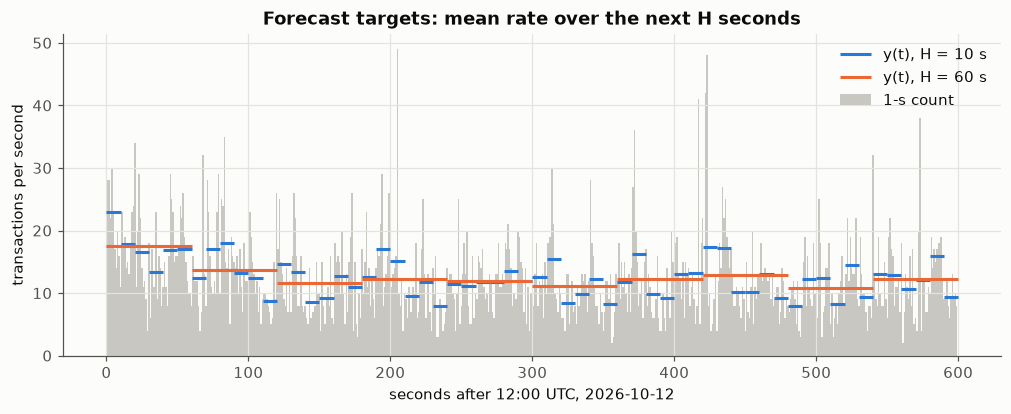

In [8]:
c = built["2026-10-12"]["arrival_count"].to_numpy(float)
t0, span = 12 * 3600, 600
x = np.arange(span)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(x, c[t0:t0 + span], width=1.0, color="#c9c7c1", label="1-s count")
for H, colr in ((10, fc.SERIES[0]), (60, fc.SERIES[1])):
    for o in range(0, span, H):
        ax.hlines(c[t0 + o:t0 + o + H].mean(), o, o + H, color=colr, lw=2, label=f"y(t), H = {H} s" if o == 0 else None)
ax.set(xlabel="seconds after 12:00 UTC, 2026-10-12", ylabel="transactions per second", title="Forecast targets: mean rate over the next H seconds")
ax.legend(loc="upper right"); plt.show()

In [9]:
pd.DataFrame([
    {"candidate": "arrival rate (tx/s)", "decision": "PRIMARY", "why": "offered load: what a Fabric workload generator and the predictive controller consume; complete, persistent"},
    {"candidate": "declared gas demand (Mgas/s)", "decision": "secondary", "why": "Ethereum's resource measure; but a declared limit, not gas used, and not a Fabric quantity; burst-dominated"},
    {"candidate": "median fee cap (gwei)", "decision": "rejected", "why": "a price, not load"},
    {"candidate": "calldata bytes/s", "decision": "rejected", "why": "would map only to Fabric payload size, which experiments hold fixed"},
    {"candidate": "inclusion delay", "decision": "rejected", "why": "known only after inclusion: leakage"},
])

,candidate,decision,why
0,arrival rate (tx/s),PRIMARY,offered load: what a Fabric workload generator...
1,declared gas demand (Mgas/s),secondary,Ethereum's resource measure; but a declared li...
2,median fee cap (gwei),rejected,"a price, not load"
3,calldata bytes/s,rejected,"would map only to Fabric payload size, which e..."
4,inclusion delay,rejected,known only after inclusion: leakage


## 6. The two targets over both days

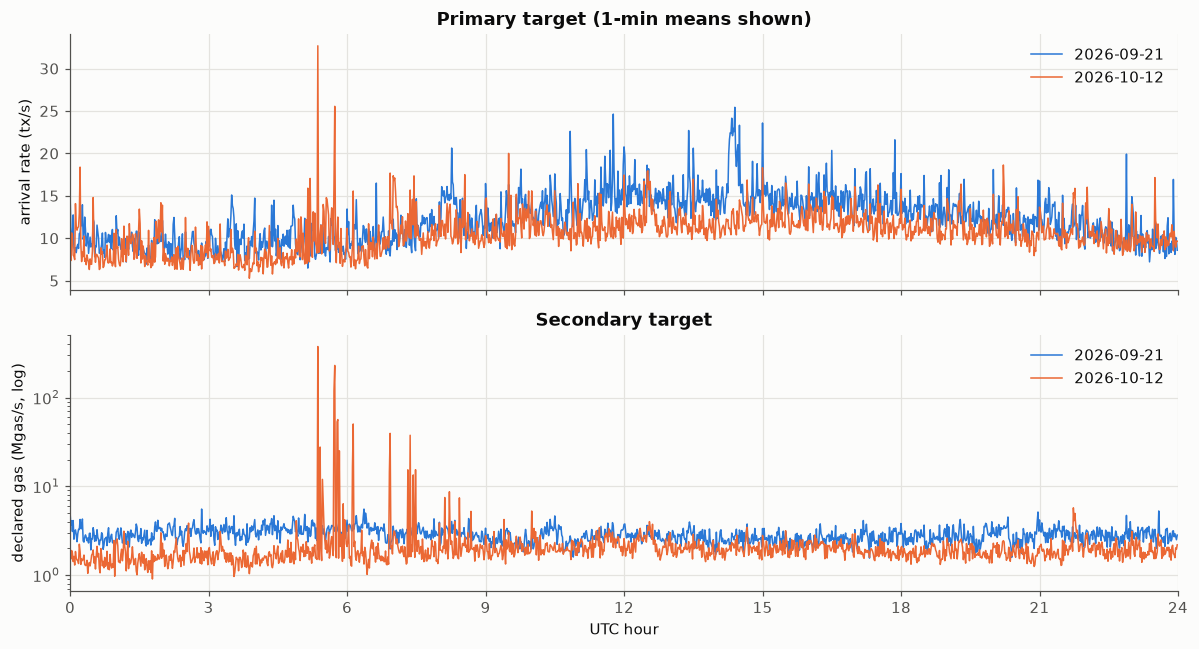

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for d in fc.DATES:
    h = np.arange(1440) / 60
    axes[0].plot(h, built[d]["arrival_count"].to_numpy(float).reshape(-1, 60).mean(1), color=fc.DAY_COLOR[d], lw=1, label=d)
    axes[1].plot(h, built[d]["gas_limit_sum"].to_numpy(float).reshape(-1, 60).mean(1) / 1e6, color=fc.DAY_COLOR[d], lw=1, label=d)
axes[0].set(ylabel="arrival rate (tx/s)", title="Primary target (1-min means shown)")
axes[1].set(yscale="log", ylabel="declared gas (Mgas/s, log)", xlabel="UTC hour", title="Secondary target", xlim=(0, 24), xticks=range(0, 25, 3))
for ax in axes: ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

## Preprocessing decisions (summary)

| Decision | Choice |
|---|---|
| Raw data | read in place; SHA-256 verified before every read; never edited |
| Timezone | UTC only |
| Duplicates | none exist (0 duplicate hashes); nothing removed |
| Replacement transactions, exact ties, bursts, never-included transactions | kept: they are real arrivals |
| Empty seconds | true zeros (counts/sums); medians NaN |
| Resampling / interpolation / transformation | none; target in the units a workload generator uses (tx/s) |
| Joining the days | never |

Next: `../forecasting/04_flashbots_forecasting_benchmark.ipynb`.